In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn xgboost shap

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from sklearn.model_selection import GridSearchCV

from xgboost import XGBClassifier

import shap

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("LC_loans_granting_model_dataset.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  object 
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  object 
 8   purpose           1347681 non-null  object 
 9   home_ownership_n  1347681 non-null  object 
 10  addr_state        1347681 non-null  object 
 11  zip_code          1347680 non-null  object 
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  object 
 14  desc              119099 non-null   object 
dtypes: float64(3), int64(4), object(8)
memory usage: 

In [5]:
df.describe()

,id,revenue,dti_n,loan_amnt,fico_n,experience_c,Default
count,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06
mean,5.621359e+07,7.736968e+04,1.829909e+01,1.440823e+04,6.981589e+02,9.999814e-01,1.997869e-01
std,3.839501e+07,7.036299e+04,1.115214e+01,8.715347e+03,3.184872e+01,4.306977e-03,3.998402e-01
min,5.473400e+04,1.896000e+03,0.000000e+00,5.000000e+02,6.120000e+02,0.000000e+00,0.000000e+00
25%,1.970651e+07,4.660000e+04,1.182000e+01,7.975000e+03,6.720000e+02,1.000000e+00,0.000000e+00
50%,5.766422e+07,6.500000e+04,1.763000e+01,1.200000e+04,6.920000e+02,1.000000e+00,0.000000e+00
75%,8.449505e+07,9.200000e+04,2.407000e+01,2.000000e+04,7.120000e+02,1.000000e+00,0.000000e+00
max,1.456364e+08,1.099920e+07,9.990000e+02,4.000000e+04,8.475000e+02,1.000000e+00,1.000000e+00


In [6]:
#Check Missing values
missing = df.isnull().sum().sort_values(ascending=False)
print(missing)

desc                1228582
title                 16657
zip_code                  1
dti_n                     0
id                        0
issue_d                   0
revenue                   0
experience_c              0
fico_n                    0
loan_amnt                 0
emp_length                0
addr_state                0
home_ownership_n          0
purpose                   0
Default                   0
dtype: int64


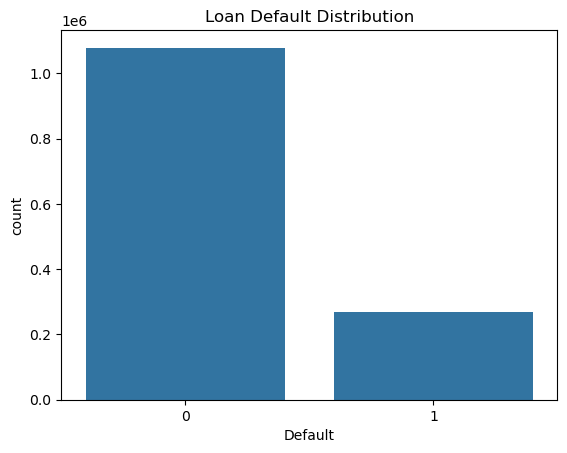

In [7]:
# Target variable Distribution
sns.countplot(x="Default", data=df)

plt.title("Loan Default Distribution")

plt.show()

In [8]:
df["revenue"].describe()

count    1.347681e+06
mean     7.736968e+04
std      7.036299e+04
min      1.896000e+03
25%      4.660000e+04
50%      6.500000e+04
75%      9.200000e+04
max      1.099920e+07
Name: revenue, dtype: float64

In [9]:
df["revenue"].sort_values(ascending=False).head(10)

401581    10999200.0
574869     9550000.0
974244     9522972.0
203890     9500000.0
902723     9300000.0
497338     9225000.0
35666      9000000.0
191930     8900060.0
356764     8706582.0
21834      8700000.0
Name: revenue, dtype: float64

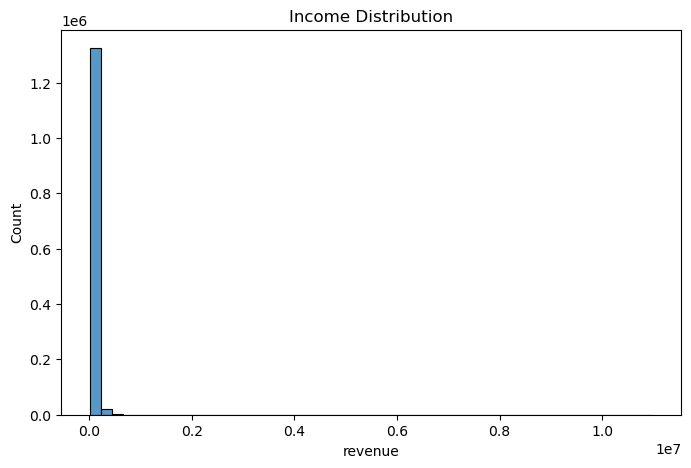

In [10]:
#EDA
#Income Distribution

plt.figure(figsize=(8,5))

sns.histplot(df["revenue"], bins=50)

plt.title("Income Distribution")

plt.show()

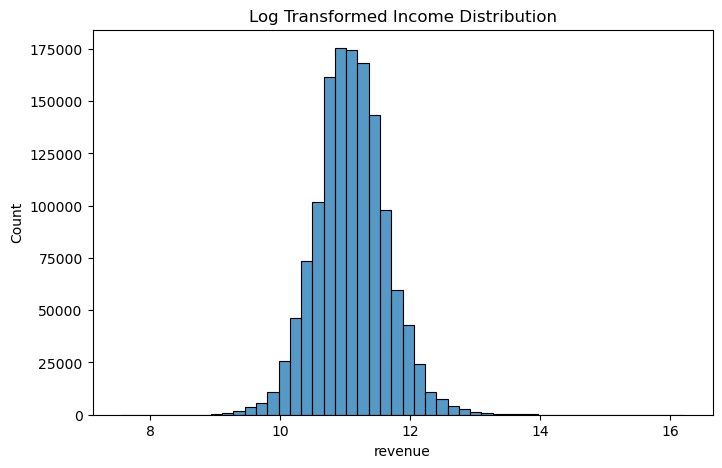

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(np.log1p(df["revenue"]), bins=50)

plt.title("Log Transformed Income Distribution")

plt.show()

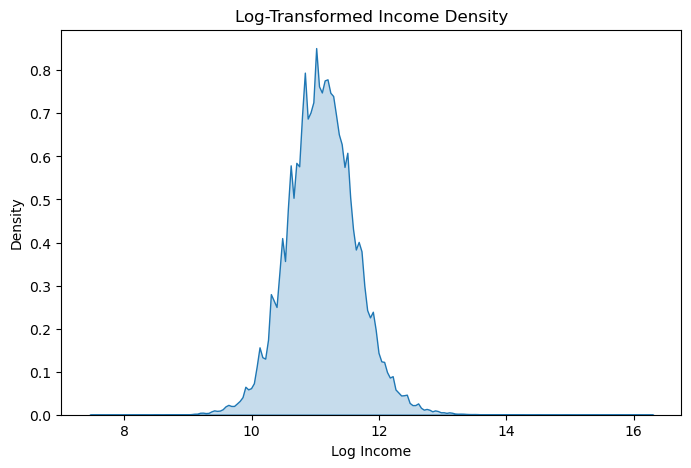

In [12]:
plt.figure(figsize=(8,5))

sns.kdeplot(np.log1p(df["revenue"]), fill=True)

plt.title("Log-Transformed Income Density")

plt.xlabel("Log Income")

plt.show()

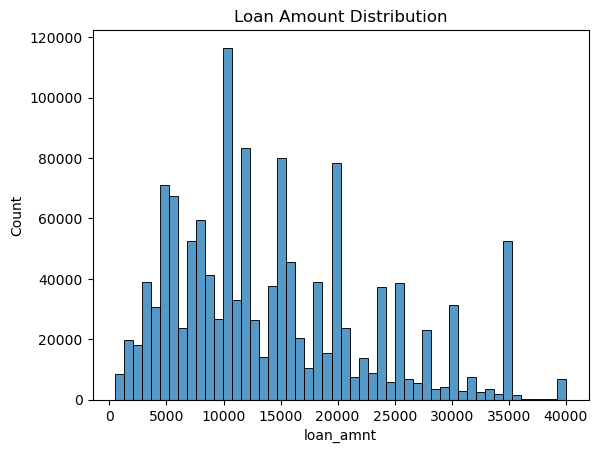

In [13]:
#Loan amount distribution

sns.histplot(df["loan_amnt"], bins=50)

plt.title("Loan Amount Distribution")

plt.show()

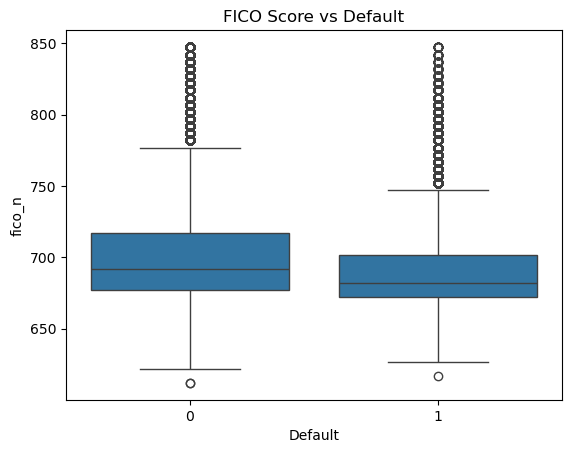

In [14]:
#FICO score vs default
sns.boxplot(x="Default", y="fico_n", data=df)

plt.title("FICO Score vs Default")

plt.show()

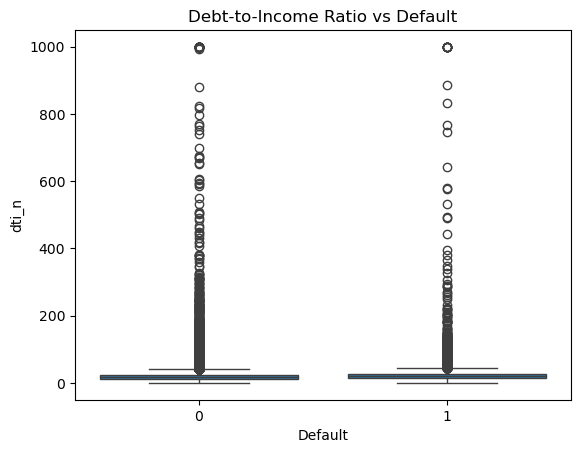

In [15]:
#Debt-to-Income vs Default
sns.boxplot(x="Default", y="dti_n", data=df)

plt.title("Debt-to-Income Ratio vs Default")

plt.show()

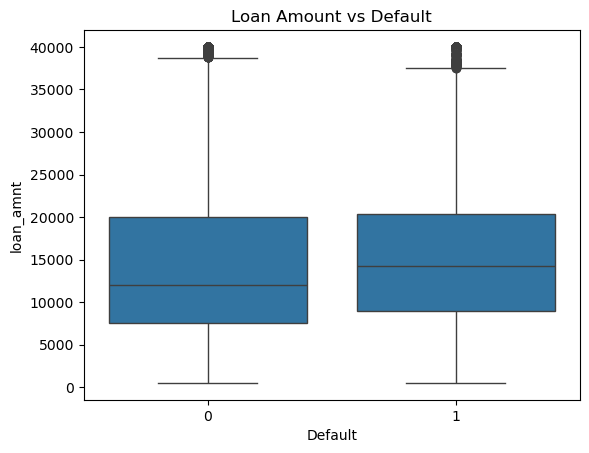

In [16]:
#Loan Amount vs Default
sns.boxplot(x="Default", y="loan_amnt", data=df)

plt.title("Loan Amount vs Default")

plt.show()

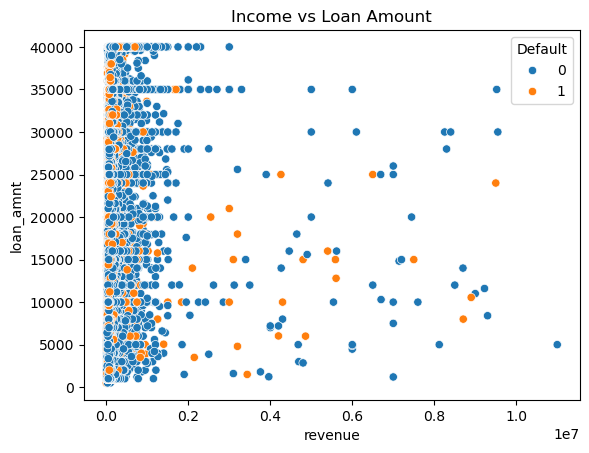

In [17]:
#Income vs Loan Amount
sns.scatterplot(x="revenue", y="loan_amnt", hue="Default", data=df)

plt.title("Income vs Loan Amount")

plt.show()

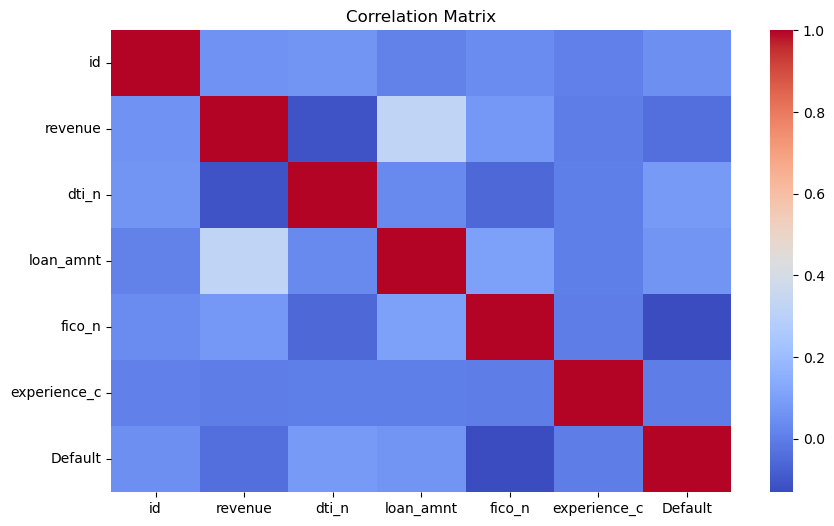

In [18]:
#Correlation Matrix
plt.figure(figsize=(10,6))

sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [19]:
#Encode Categorical Variables
categorical_cols = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state",
    "zip_code"
]

le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [20]:
#Drop Unnecessary Columns
df = df.drop(columns=["id","issue_d","title","desc"])

In [21]:
#Define Features and Target
X = df.drop("Default", axis=1)
y = df["Default"]

In [22]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

            Feature     Score
4      experience_c  0.130709
7  home_ownership_n  0.074921
6           purpose  0.042233
3            fico_n  0.019394
5        emp_length  0.016197
2         loan_amnt  0.010483
8        addr_state  0.009403
1             dti_n  0.005828
0           revenue  0.003827
9          zip_code  0.002570


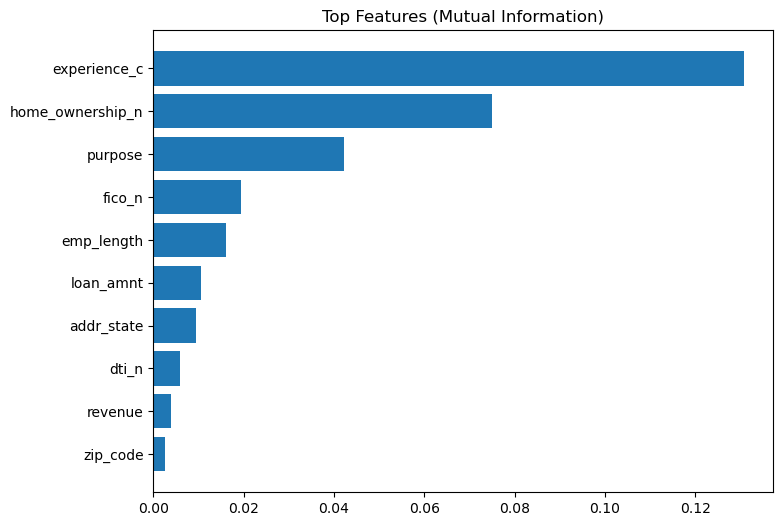

In [23]:
#Feature Selection
from sklearn.feature_selection import mutual_info_classif, RFE

mi_scores = mutual_info_classif(X_train, y_train)

mi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": mi_scores
})

mi_df = mi_df.sort_values(by="Score", ascending=False)

print(mi_df.head(10))

plt.figure(figsize=(8,6))
plt.barh(mi_df["Feature"][:10], mi_df["Score"][:10])
plt.gca().invert_yaxis()
plt.title("Top Features (Mutual Information)")
plt.show()

In [24]:
#Recursive Feature Elimination
lr = LogisticRegression(max_iter=1000)

rfe = RFE(
    lr,
    n_features_to_select=10
)

rfe.fit(X_train, y_train)

selected_features = X_train.columns[rfe.support_]

print("Selected Features:")

print(selected_features)

Selected Features:
Index(['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length',
       'purpose', 'home_ownership_n', 'addr_state', 'zip_code'],
      dtype='object')


In [25]:
#Logistic Regression Model
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [26]:
#Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [27]:
#XGBoost Model
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

In [28]:
#Model Evaluation Function

def evaluate_model(name, y_test, predictions):

    print("Model:", name)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("\nClassification Report:")

    print(classification_report(
        y_test,
        predictions
    ))

    print("\nConfusion Matrix:")

    print(confusion_matrix(
        y_test,
        predictions
    ))

#Evaluate Models
evaluate_model("Logistic Regression", y_test, lr_pred)

evaluate_model("Random Forest", y_test, rf_pred)

evaluate_model("XGBoost", y_test, xgb_pred)

Model: Logistic Regression
Accuracy: 0.8005691240905701

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89    215878
           1       0.34      0.00      0.00     53659

    accuracy                           0.80    269537
   macro avg       0.57      0.50      0.45    269537
weighted avg       0.71      0.80      0.71    269537


Confusion Matrix:
[[215685    193]
 [ 53561     98]]
Model: Random Forest
Accuracy: 0.7976010714669971

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.99      0.89    215878
           1       0.41      0.04      0.07     53659

    accuracy                           0.80    269537
   macro avg       0.61      0.51      0.48    269537
weighted avg       0.73      0.80      0.72    269537


Confusion Matrix:
[[212967   2911]
 [ 51643   2016]]
Model: XGBoost
Accuracy: 0.8009883615236498

Classification Report:
              pr

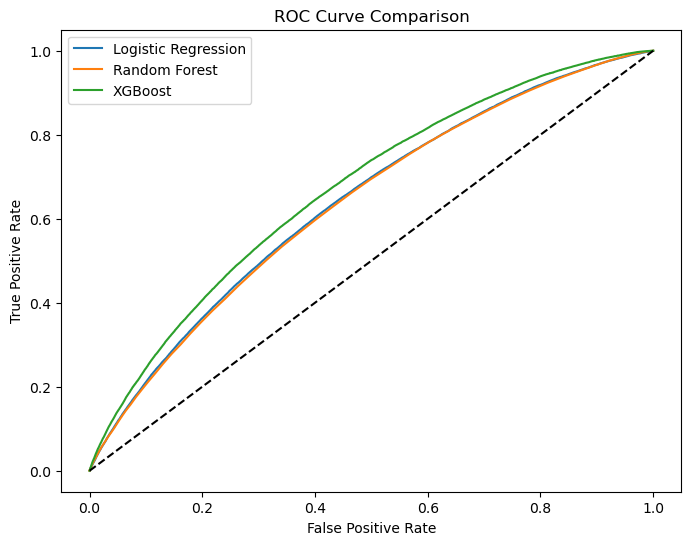

In [29]:
#ROC curve Comparison
lr_probs = lr_model.predict_proba(X_test)[:,1]
rf_probs = rf_model.predict_proba(X_test)[:,1]
xgb_probs = xgb_model.predict_proba(X_test)[:,1]

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(8,6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression")

plt.plot(rf_fpr, rf_tpr, label="Random Forest")

plt.plot(xgb_fpr, xgb_tpr, label="XGBoost")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

In [ ]:
#Hyperparameter Tuning(Random Forest)

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    "n_estimators":[100,200],
    "max_depth":[5,10,None],
    "min_samples_split":[2,5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(),
    param_grid_rf,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

grid_rf.fit(X_train,y_train)

best_rf = grid_rf.best_estimator_

print(grid_rf.best_params_)

In [ ]:
#Hyperparameter Tuning (XGBoost)

param_grid_xgb = {
    "n_estimators":[100,200],
    "max_depth":[4,6],
    "learning_rate":[0.05,0.1]
}

grid_xgb = GridSearchCV(
    XGBClassifier(),
    param_grid_xgb,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

grid_xgb.fit(X_train,y_train)

best_xgb = grid_xgb.best_estimator_

print(grid_xgb.best_params_)

In [ ]:
#Cross Validation

cv_scores = cross_val_score(
    best_xgb,
    X,
    y,
    cv=5,
    scoring="roc_auc"
)

print("CV Scores:", cv_scores)

print("Average CV Score:", cv_scores.mean())

In [ ]:
#Feature Importance

importances = best_rf.feature_importances_

feat_importance = pd.DataFrame({
    "Feature":X.columns,
    "Importance":importances
})

feat_importance = feat_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feat_importance.head(10)
)

plt.title("Top Features")

plt.show()

In [ ]:
#SHAP Explainability

explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer.shap_values(X_test)

In [ ]:
#SHAP Summary Plot

shap.summary_plot(
    shap_values,
    X_test
)

In [ ]:
#SHAP Dependance Plot
shap.dependence_plot(
    "dti_n",
    shap_values,
    X_test
)

In [ ]:
#SHAP Waterfall Plot
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test.iloc[0],
        feature_names=X_test.columns
    )
)

In [ ]:
#Bias/Fairness Analysis

df_test = X_test.copy()

df_test["prediction"] = best_xgb.predict(X_test)

df_test["actual"] = y_test

fairness = df_test.groupby(
    "home_ownership_n"
)["prediction"].mean()

print(fairness)

In [ ]:
#Final Model Comparison Table

results = pd.DataFrame({

"Model":[
"Logistic Regression",
"Random Forest",
"XGBoost"
],

"Accuracy":[
accuracy_score(y_test, lr_pred),
accuracy_score(y_test, rf_pred),
accuracy_score(y_test, xgb_pred)
],

"ROC_AUC":[
roc_auc_score(y_test, lr_probs),
roc_auc_score(y_test, rf_probs),
roc_auc_score(y_test, xgb_probs)
]

})

print(results)